# 01 · Grant Approval — Classification on Imbalanced Data

**Question.** Given the details of a research grant application, how likely is it to be approved?

**Data.** 4,113 applications with 38 features: sponsor, grant category, contract value band, research field codes
and the applicant's history (earlier successful and unsuccessful grants, publications, PhD). Only **21%** were approved.

**Approach.** Identifiers and classification codes are treated as labels, not numbers → stratified train/test split
*before* any statistic is computed → missing-value handling fitted on the training part only → one-hot encoding →
logistic regression vs. a random forest tuned with cross-validated grid search, both scored by ROC-AUC.

**Result.**

| Model | ROC-AUC, 5-fold CV | ROC-AUC, hold-out test |
|---|---|---|
| Logistic regression | 0.880 | 0.866 |
| Random forest (tuned) | 0.930 | **0.910** |

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 12345

## 1. Loading and inspecting the data

In [2]:
data = pd.read_csv('../data/grant_data_imb.csv')
print('shape:', data.shape)
data.head()

shape: (4113, 39)


,Grant.Status,Sponsor.Code,Grant.Category.Code,Contract.Value.Band...see.note.A,RFCD.Code.1,RFCD.Percentage.1,RFCD.Code.2,RFCD.Percentage.2,RFCD.Code.3,RFCD.Percentage.3,RFCD.Code.4,RFCD.Percentage.4,RFCD.Code.5,RFCD.Percentage.5,SEO.Code.1,SEO.Percentage.1,SEO.Code.2,SEO.Percentage.2,SEO.Code.3,SEO.Percentage.3,SEO.Code.4,SEO.Percentage.4,SEO.Code.5,SEO.Percentage.5,Person.ID.1,Role.1,Year.of.Birth.1,Country.of.Birth.1,Home.Language.1,Dept.No..1,Faculty.No..1,With.PHD.1,No..of.Years.in.Uni.at.Time.of.Grant.1,Number.of.Successful.Grant.1,Number.of.Unsuccessful.Grant.1,A..1,A.1,B.1,C.1
0,0,97A,30B,A,321024.0,50.0,321013.0,30.0,291502.0,20.0,0.0,0.0,0.0,0.0,730303.0,50.0,730104.0,30.0,671402.0,20.0,0.0,0.0,0.0,0.0,67037.0,CHIEF_INVESTIGATOR,1950.0,Eastern Europe,NaN,2563.0,25.0,Yes,>10 to 15,2.0,6.0,3.0,5.0,15.0,3.0
1,0,36D,10A,G,300201.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,620108.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12917.0,PRINCIPAL_SUPERVISOR,1955.0,Australia,NaN,1038.0,1.0,NaN,Less than 0,0.0,3.0,0.0,4.0,0.0,0.0
2,0,317A,30D,NaN,321013.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,730104.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28607.0,CHIEF_INVESTIGATOR,1965.0,Great Britain,NaN,2763.0,25.0,Yes,>5 to 10,4.0,3.0,6.0,25.0,14.0,14.0
3,0,62B,10B,B,321103.0,30.0,321105.0,40.0,321204.0,30.0,0.0,0.0,0.0,0.0,730211.0,50.0,730302.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,144632.0,CHIEF_INVESTIGATOR,1960.0,Australia,NaN,2848.0,25.0,NaN,Less than 0,1.0,2.0,1.0,0.0,0.0,0.0
4,0,1A,10A,NaN,270603.0,60.0,321205.0,30.0,320603.0,10.0,0.0,0.0,0.0,0.0,730114.0,60.0,730204.0,10.0,730215.0,30.0,0.0,0.0,0.0,0.0,1797.0,CHIEF_INVESTIGATOR,1960.0,North America,NaN,2678.0,25.0,Yes,>5 to 10,5.0,14.0,0.0,9.0,7.0,0.0


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4113 entries, 0 to 4112
Data columns (total 39 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Grant.Status                            4113 non-null   int64  
 1   Sponsor.Code                            3856 non-null   str    
 2   Grant.Category.Code                     3856 non-null   str    
 3   Contract.Value.Band...see.note.A        1953 non-null   str    
 4   RFCD.Code.1                             3853 non-null   float64
 5   RFCD.Percentage.1                       3853 non-null   float64
 6   RFCD.Code.2                             3853 non-null   float64
 7   RFCD.Percentage.2                       3853 non-null   float64
 8   RFCD.Code.3                             3853 non-null   float64
 9   RFCD.Percentage.3                       3853 non-null   float64
 10  RFCD.Code.4                             3853 non-null   float64
 11  RF

In [4]:
# missing values per column
na_stat = pd.DataFrame({
    'missing': data.isna().sum(),
    'share_%': (data.isna().mean() * 100).round(1)
})
na_stat[na_stat['missing'] > 0].sort_values('missing', ascending=False)

,missing,share_%
Home.Language.1,3719,90.4
Contract.Value.Band...see.note.A,2160,52.5
With.PHD.1,1781,43.3
No..of.Years.in.Uni.at.Time.of.Grant.1,759,18.5
Country.of.Birth.1,666,16.2
Faculty.No..1,449,10.9
Dept.No..1,448,10.9
Year.of.Birth.1,288,7.0
Number.of.Unsuccessful.Grant.1,287,7.0
B.1,287,7.0


Missing values are substantial: `Home.Language.1` is empty in 90% of rows and the contract value band in more
than half. Dropping these rows would discard most of the dataset, so every gap is filled deliberately instead.

## 2. Which numeric columns are really numbers?

Several columns are stored as numbers but are labels:

* `Person.ID.1` identifies the applicant;
* `Dept.No..1` and `Faculty.No..1` identify organisational units;
* `RFCD.Code.*` and `SEO.Code.*` are six-digit research-field and socio-economic-objective codes. Code `321024` is not
  "larger" than code `300201` in any meaningful sense.

Treated as quantities, they would let a model draw false conclusions from their numeric order.

In [5]:
target = data['Grant.Status']
features = data.drop(columns=['Grant.Status'])

id_column = 'Person.ID.1'
unit_columns = ['Dept.No..1', 'Faculty.No..1']
code_columns = [c for c in features.columns if c.startswith(('RFCD.Code', 'SEO.Code'))]

people = features[id_column]
applications_per_person = people.value_counts()

print('applications with a person ID:  ', people.notna().sum())
print('distinct applicants:            ', people.nunique())
print('applicants with 2+ applications:', (applications_per_person >= 2).sum())
print('most applications by one person:', applications_per_person.max())

applications with a person ID:   3826
distinct applicants:             1669
applicants with 2+ applications: 804
most applications by one person: 33


Many applicants appear several times. A model given the ID could memorise individual people ("applicant X is
usually approved") instead of learning a rule, and that knowledge is worthless for a new applicant. The ID is dropped.

Department and faculty numbers become categories. The field codes are hierarchical — the first two digits give the
broad division — so they are reduced to that division: 549 distinct six-digit values would be far too sparse for
3,000 training rows. A code of `0` means "no further field listed".

In [6]:
def code_division(codes):
    """Six-digit field code -> two-digit division; 0 -> 'none'; missing stays missing."""
    result = pd.Series(np.nan, index=codes.index, dtype='object')
    result[codes == 0] = 'none'
    listed = codes.notna() & (codes != 0)
    result[listed] = (codes[listed] // 10000).astype(int).astype(str).str.zfill(2)
    return result


features = features.drop(columns=[id_column])

for col in unit_columns:
    features[col] = features[col].map(lambda v: np.nan if pd.isna(v) else str(int(v)))

for col in code_columns:
    features[col] = code_division(features[col])

numeric_cols = features.select_dtypes(include='number').columns.tolist()
categorical_cols = [c for c in features.columns if c not in numeric_cols]

print('numeric features:    ', len(numeric_cols))
print('categorical features:', len(categorical_cols))
print()
print('RFCD.Code.1 divisions:', features['RFCD.Code.1'].nunique(), '| examples:',
      features['RFCD.Code.1'].dropna().unique()[:8])

numeric features:     17
categorical features: 20

RFCD.Code.1 divisions: 24 | examples: ['32' '30' '27' '24' '26' '38' '37' '33']


## 3. Train/test split — before any statistic is computed

The split comes first, so that nothing learned during preprocessing (such as a column mean) can carry information
from the test set into training. It is stratified to keep the 21% approval rate in both parts.

In [7]:
features_train, features_test, target_train, target_test = train_test_split(
    features, target,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=target
)

print('train:', features_train.shape)
print('test: ', features_test.shape)

train: (3084, 37)
test:  (1029, 37)


## 4. Preprocessing fitted on the training part

* **Numeric gaps** are filled in two ways side by side — with the training mean and with zero — so the model can use
  whichever signal works better. The original columns are then dropped.
* **Categorical gaps**: a missing PhD flag means no PhD; every other gap becomes an explicit `unknown` category.
* **One-hot encoding** uses the categories seen in training; the test set is aligned to the same columns.

In [8]:
train_means = features_train[numeric_cols].mean()


def prepare(frame):
    result = frame.copy()

    for col in numeric_cols:
        result[col + '_mean'] = result[col].fillna(train_means[col])
        result[col + '_zero'] = result[col].fillna(0)
    result = result.drop(columns=numeric_cols)

    for col in categorical_cols:
        result[col] = result[col].astype('object').str.strip()

    # a missing PhD flag means the applicant has no PhD
    result['With.PHD.1'] = result['With.PHD.1'].fillna('No')

    # every other categorical gap becomes an explicit category
    for col in categorical_cols:
        if col != 'With.PHD.1':
            result[col] = result[col].fillna('unknown')

    return result


prepared_train = prepare(features_train)
prepared_test = prepare(features_test)

print('missing values left: train =', prepared_train.isna().sum().sum(),
      '| test =', prepared_test.isna().sum().sum())
prepared_train[['Year.of.Birth.1_mean', 'Year.of.Birth.1_zero', 'Dept.No..1', 'RFCD.Code.1']].head(10)

missing values left: train = 0 | test = 0


,Year.of.Birth.1_mean,Year.of.Birth.1_zero,Dept.No..1,RFCD.Code.1
3310,1960.0,1960.0,528,42
3058,1965.0,1965.0,2523,32
2638,1945.0,1945.0,2678,32
2380,1950.0,1950.0,2523,unknown
1,1955.0,1955.0,1038,30
2339,1960.0,1960.0,2178,23
2346,1975.0,1975.0,2523,23
1497,1965.0,1965.0,2563,32
167,1965.0,1965.0,2883,32
2697,1975.0,1975.0,2523,23


In [9]:
for col in categorical_cols:
    values = prepared_train[col].unique()
    print('{} | unique values in train: {}'.format(col, prepared_train[col].nunique()))
    print('   ', values[:12], '...' if len(values) > 12 else '')

Sponsor.Code | unique values in train: 199
    ['2B' 'unknown' '4D' '36D' '77A' '24D' '21A' '18B' '65A' '195C' '60D'
 '42B'] ...
Grant.Category.Code | unique values in train: 13
    ['10A' 'unknown' '30B' '50A' '20C' '30D' '20A' '30C' '10B' '30G' '30E'
 '30F'] ...
Contract.Value.Band...see.note.A | unique values in train: 17
    ['unknown' 'G' 'F' 'A' 'B' 'D' 'C' 'E' 'J' 'H' 'I' 'O'] ...
RFCD.Code.1 | unique values in train: 25
    ['42' '32' 'unknown' '30' '23' '43' '24' '35' '27' '28' '26' '34'] ...
RFCD.Code.2 | unique values in train: 24
    ['41' '27' 'none' 'unknown' '23' '32' '30' '36' '24' '35' '26' '28'] ...
RFCD.Code.3 | unique values in train: 24
    ['41' '32' 'none' 'unknown' '29' '27' '37' '24' '34' '26' '28' '23'] ...
RFCD.Code.4 | unique values in train: 18
    ['none' 'unknown' '36' '32' '29' '23' '27' '26' '24' '25' '28' '30'] ...
RFCD.Code.5 | unique values in train: 10
    ['none' 'unknown' '32' '27' '29' '37' '30' '24' '36' '41'] 
SEO.Code.1 | unique values in trai

In [10]:
features_train_ohe = pd.get_dummies(prepared_train, drop_first=True)
# the test set gets exactly the training columns; categories unseen in training fall into the baseline
features_test_ohe = (pd.get_dummies(prepared_test)
                     .reindex(columns=features_train_ohe.columns, fill_value=0))

print('features before encoding:', prepared_train.shape[1])
print('features after encoding: ', features_train_ohe.shape[1])
print('test columns aligned:    ', list(features_test_ohe.columns) == list(features_train_ohe.columns))

features before encoding:

 54
features after encoding:  572
test columns aligned:     True


In [11]:
numeric_filled = [c for c in features_train_ohe.columns
                  if c.endswith('_mean') or c.endswith('_zero')]

scaler = StandardScaler()
scaler.fit(features_train_ohe[numeric_filled])

features_train_sc = features_train_ohe.astype(float).copy()
features_test_sc = features_test_ohe.astype(float).copy()
features_train_sc[numeric_filled] = scaler.transform(features_train_ohe[numeric_filled])
features_test_sc[numeric_filled] = scaler.transform(features_test_ohe[numeric_filled])

features_train_sc[numeric_filled].describe().T[['mean', 'std', 'min', 'max']].head()

,mean,std,min,max
RFCD.Percentage.1_mean,-1.244141e-16,1.000162,-2.670636,0.970096
RFCD.Percentage.1_zero,1.059824e-16,1.000162,-2.190223,0.944606
RFCD.Percentage.2_mean,9.215859e-18,1.000162,-0.944209,3.874357
RFCD.Percentage.2_zero,1.843172e-17,1.000162,-0.860433,3.833485
RFCD.Percentage.3_mean,-5.183921e-17,1.000162,-0.610399,5.428404


## 5. Class balance

Grant.Status
0    2444
1     640
Name: count, dtype: int64

Grant.Status
0    0.792
1    0.208
Name: proportion, dtype: float64


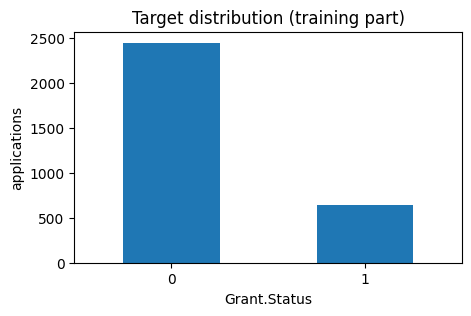

In [12]:
print(target_train.value_counts())
print()
print(target_train.value_counts(normalize=True).round(3))

target_train.value_counts().plot(kind='bar', rot=0, figsize=(5, 3),
                                 title='Target distribution (training part)')
plt.xlabel('Grant.Status')
plt.ylabel('applications')
plt.show()

Roughly one approval for every four rejections. Accuracy would be misleading here — a model that rejects everything
scores 79% — so the models are compared by **ROC-AUC**, and both use `class_weight='balanced'` so the minority
class carries proportionate weight during training.

## 6. Logistic regression

In [13]:
model_lr = LogisticRegression(solver='liblinear',
                              class_weight='balanced',
                              random_state=RANDOM_STATE)

scores = cross_val_score(model_lr, features_train_sc, target_train,
                         cv=5, scoring='roc_auc')

print('ROC-AUC per fold:', scores.round(4))
print('mean ROC-AUC, cross-validation: {:.4f}'.format(scores.mean()))

ROC-AUC per fold: [0.8698 0.8667 0.8689 0.9135 0.881 ]
mean ROC-AUC, cross-validation: 0.8800


In [14]:
model_lr.fit(features_train_sc, target_train)
probabilities_lr = model_lr.predict_proba(features_test_sc)[:, 1]
roc_auc_lr = roc_auc_score(target_test, probabilities_lr)

print('logistic regression, ROC-AUC on test: {:.4f}'.format(roc_auc_lr))

logistic regression, ROC-AUC on test: 0.8656


### Top 10 features by coefficient magnitude

In [15]:
coefficients = pd.DataFrame({
    'feature': features_train_sc.columns,
    'coefficient': model_lr.coef_[0],
    'magnitude': np.abs(model_lr.coef_[0])
}).sort_values('magnitude', ascending=False)

coefficients.head(10).reset_index(drop=True).round(4)

,feature,coefficient,magnitude
0,Contract.Value.Band...see.note.A_unknown,-2.8727,2.8727
1,Sponsor.Code_6B,-2.5952,2.5952
2,Contract.Value.Band...see.note.A_J,-2.2009,2.2009
3,Sponsor.Code_36D,2.1206,2.1206
4,Sponsor.Code_24D,-2.0851,2.0851
5,Sponsor.Code_228D,1.8273,1.8273
6,Sponsor.Code_226B,1.8245,1.8245
7,Sponsor.Code_266B,1.7515,1.7515
8,Sponsor.Code_75C,1.6403,1.6403
9,Sponsor.Code_33A,-1.5851,1.5851


In [16]:
# the same ranking restricted to the numeric features
coefficients[coefficients['feature'].isin(numeric_filled)].head(10).reset_index(drop=True).round(4)

,feature,coefficient,magnitude
0,Number.of.Unsuccessful.Grant.1_zero,-0.7882,0.7882
1,Number.of.Unsuccessful.Grant.1_mean,-0.6254,0.6254
2,Number.of.Successful.Grant.1_mean,0.5729,0.5729
3,Number.of.Successful.Grant.1_zero,0.4086,0.4086
4,Year.of.Birth.1_zero,0.2660,0.2660
5,Year.of.Birth.1_mean,-0.2608,0.2608
6,RFCD.Percentage.1_zero,0.2484,0.2484
7,B.1_zero,-0.1239,0.1239
8,A.1_mean,0.1215,0.1215
9,C.1_mean,0.1064,0.1064


## 7. Random forest with grid search

In [17]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE,
                           class_weight='balanced',
                           n_jobs=-1),
    param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)

grid_search.fit(features_train_sc, target_train)

print('best parameters:', grid_search.best_params_)
print('best ROC-AUC, cross-validation: {:.4f}'.format(grid_search.best_score_))

best parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}
best ROC-AUC, cross-validation: 0.9297


In [18]:
results = pd.DataFrame(grid_search.cv_results_)[
    ['param_n_estimators', 'param_max_depth', 'param_min_samples_leaf', 'mean_test_score']
].sort_values('mean_test_score', ascending=False)

results.reset_index(drop=True).round(4)

,param_n_estimators,param_max_depth,param_min_samples_leaf,mean_test_score
0,300,20,1,0.9297
1,300,10,1,0.9293
2,100,20,1,0.9282
3,300,None,1,0.9266
4,100,None,1,0.9256
5,300,20,5,0.9255
6,300,None,5,0.9254
7,100,10,1,0.9253
8,300,10,5,0.9243
9,100,None,5,0.9232


In [19]:
model_rf = grid_search.best_estimator_
probabilities_rf = model_rf.predict_proba(features_test_sc)[:, 1]
roc_auc_rf = roc_auc_score(target_test, probabilities_rf)

print('random forest, ROC-AUC on test: {:.4f}'.format(roc_auc_rf))

random forest, ROC-AUC on test: 0.9102


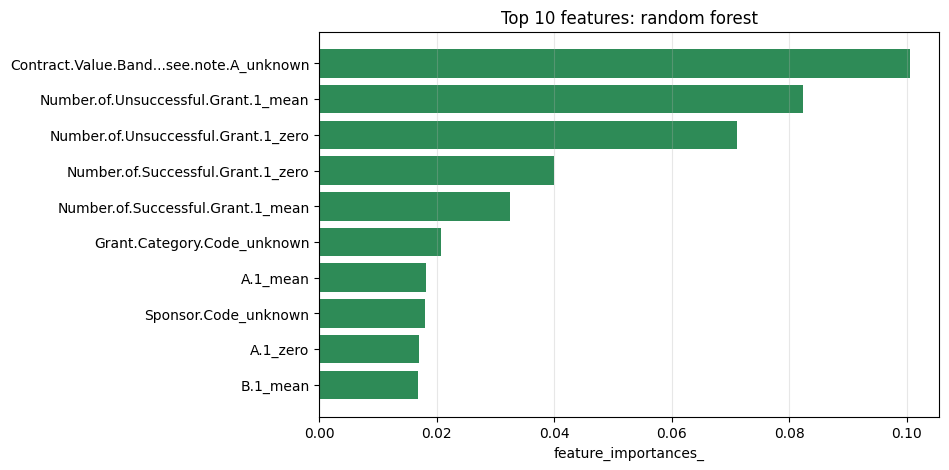

,feature,importance
0,Contract.Value.Band...see.note.A_unknown,0.1005
1,Number.of.Unsuccessful.Grant.1_mean,0.0823
2,Number.of.Unsuccessful.Grant.1_zero,0.0711
3,Number.of.Successful.Grant.1_zero,0.0400
4,Number.of.Successful.Grant.1_mean,0.0325
5,Grant.Category.Code_unknown,0.0206
6,A.1_mean,0.0181
7,Sponsor.Code_unknown,0.0179
8,A.1_zero,0.0169
9,B.1_mean,0.0168


In [20]:
importances = pd.DataFrame({
    'feature': features_train_sc.columns,
    'importance': model_rf.feature_importances_
}).sort_values('importance', ascending=False)

top10_rf = importances.head(10)

plt.figure(figsize=(8, 5))
plt.barh(top10_rf['feature'][::-1], top10_rf['importance'][::-1], color='seagreen')
plt.xlabel('feature_importances_')
plt.title('Top 10 features: random forest')
plt.grid(axis='x', alpha=0.3)
plt.show()

top10_rf.reset_index(drop=True).round(4)

## 8. Conclusions

| Model | ROC-AUC, 5-fold CV | ROC-AUC, test |
|---|---|---|
| Logistic regression | 0.8800 | 0.8656 |
| Random forest | 0.9297 | 0.9102 |

**The random forest wins** — 0.9102 against 0.8656 on the test set. After one-hot encoding the model sees 572
columns, many of them rare sponsor and field categories, and the data contains non-linear interactions; a linear model
can only add up each feature's separate contribution. Both models are far better than random, so the task is solvable
with these features.

**What drives approval, according to the models:**

1. **Unknown contract value.** For the forest, `Contract.Value.Band...see.note.A_unknown` is the most important
   feature (importance 0.10); for the regression it has the largest coefficient (−2.87). Applications that do not
   state the funding amount are noticeably less likely to be approved.
2. **The sponsor.** `Sponsor.Code` dummies take 8 of the regression's top 10 places, and `Sponsor.Code_unknown` is in
   the forest's top 10. Who funds the grant strongly affects its chances.
3. **Track record.** `Number.of.Unsuccessful.Grant.1` and `Number.of.Successful.Grant.1` are the strongest numeric
   features for both models, and the applicant's publication counts (`A.1`, `B.1`) also reach the forest's top 10.

**Why the result can be trusted for new applicants.**

* The train/test split happens before any statistic is computed, and every value used to fill gaps comes from the
  training part only, so no information from the test set reaches the model.
* The applicant ID is removed: with 804 people applying more than once, a model could otherwise memorise individuals
  instead of learning what makes an application successful.
* Department and faculty numbers and field codes are used as categories, so the model cannot read meaning into their
  numeric order.